In this notebook I want to estimate the wavefront curvature of the beam before the 100 mm lens, this measruement was done by Abi on 29-30 Sep. THis will help us choose a lens that produces the right beam size needed to optimise the tradeoff between linewidth and SNR.

References: H. Kogelnik and T. Li, "Laser Beams and Resonators," Appl. Opt. 5, 1550-1567 (1966)

In [1]:
import numpy as np

wavelength = 778e-9  # m

# Array order: [x, y]. All lengths in metres.
waist_radius = np.array([69e-6, 100e-6]) 
waist_radius_uncertainty = np.array([6e-6, 6e-6])

waist_distance = np.array([123e-3, 116e-3])
distance_uncertainty = np.array([3e-3, 2e-3])

M2 = np.array([1.2, 2.3])  # Already M² values
M2_uncertainty = np.array([0.1, 0.1])

# Effective Rayleigh lengths
z_R = np.pi * waist_radius**2 / (M2 * wavelength)
u = waist_distance / z_R
sqrt_term = np.sqrt(1 + u**2)

# Beam radii immediately before the thin lens
radius_at_lens = waist_radius * sqrt_term

# Partial derivatives; each holds the other inputs fixed
dw_dd = waist_radius * u / (z_R * sqrt_term)
dw_dM2 = waist_radius * u**2 / (M2 * sqrt_term)
dw_dw0 = (1 - u**2) / sqrt_term

# First-order propagation of independent uncertainties
radius_uncertainty = np.sqrt(
    (dw_dd * distance_uncertainty)**2
    + (dw_dM2 * M2_uncertainty)**2
    + (dw_dw0 * waist_radius_uncertainty)**2
)

for i, axis in enumerate(["x", "y"]):
    print(f"{axis} axis:")
    print(
        f"  Radius   = {radius_at_lens[i] * 1e6:.1f}"
        f" ± {radius_uncertainty[i] * 1e6:.1f} µm"
    )
    print(
        f"  Diameter = {2 * radius_at_lens[i] * 1e3:.3f}"
        f" ± {2 * radius_uncertainty[i] * 1e3:.3f} mm"
    )

x axis:
  Radius   = 534.2 ± 64.0 µm
  Diameter = 1.068 ± 0.128 mm
y axis:
  Radius   = 668.2 ± 49.0 µm
  Diameter = 1.336 ± 0.098 mm


## Data from Cameron recommends:

![Screenshot 2026-11-23 at 12.17.08.png](<attachment:Screenshot 2026-11-23 at 12.17.08.png>)

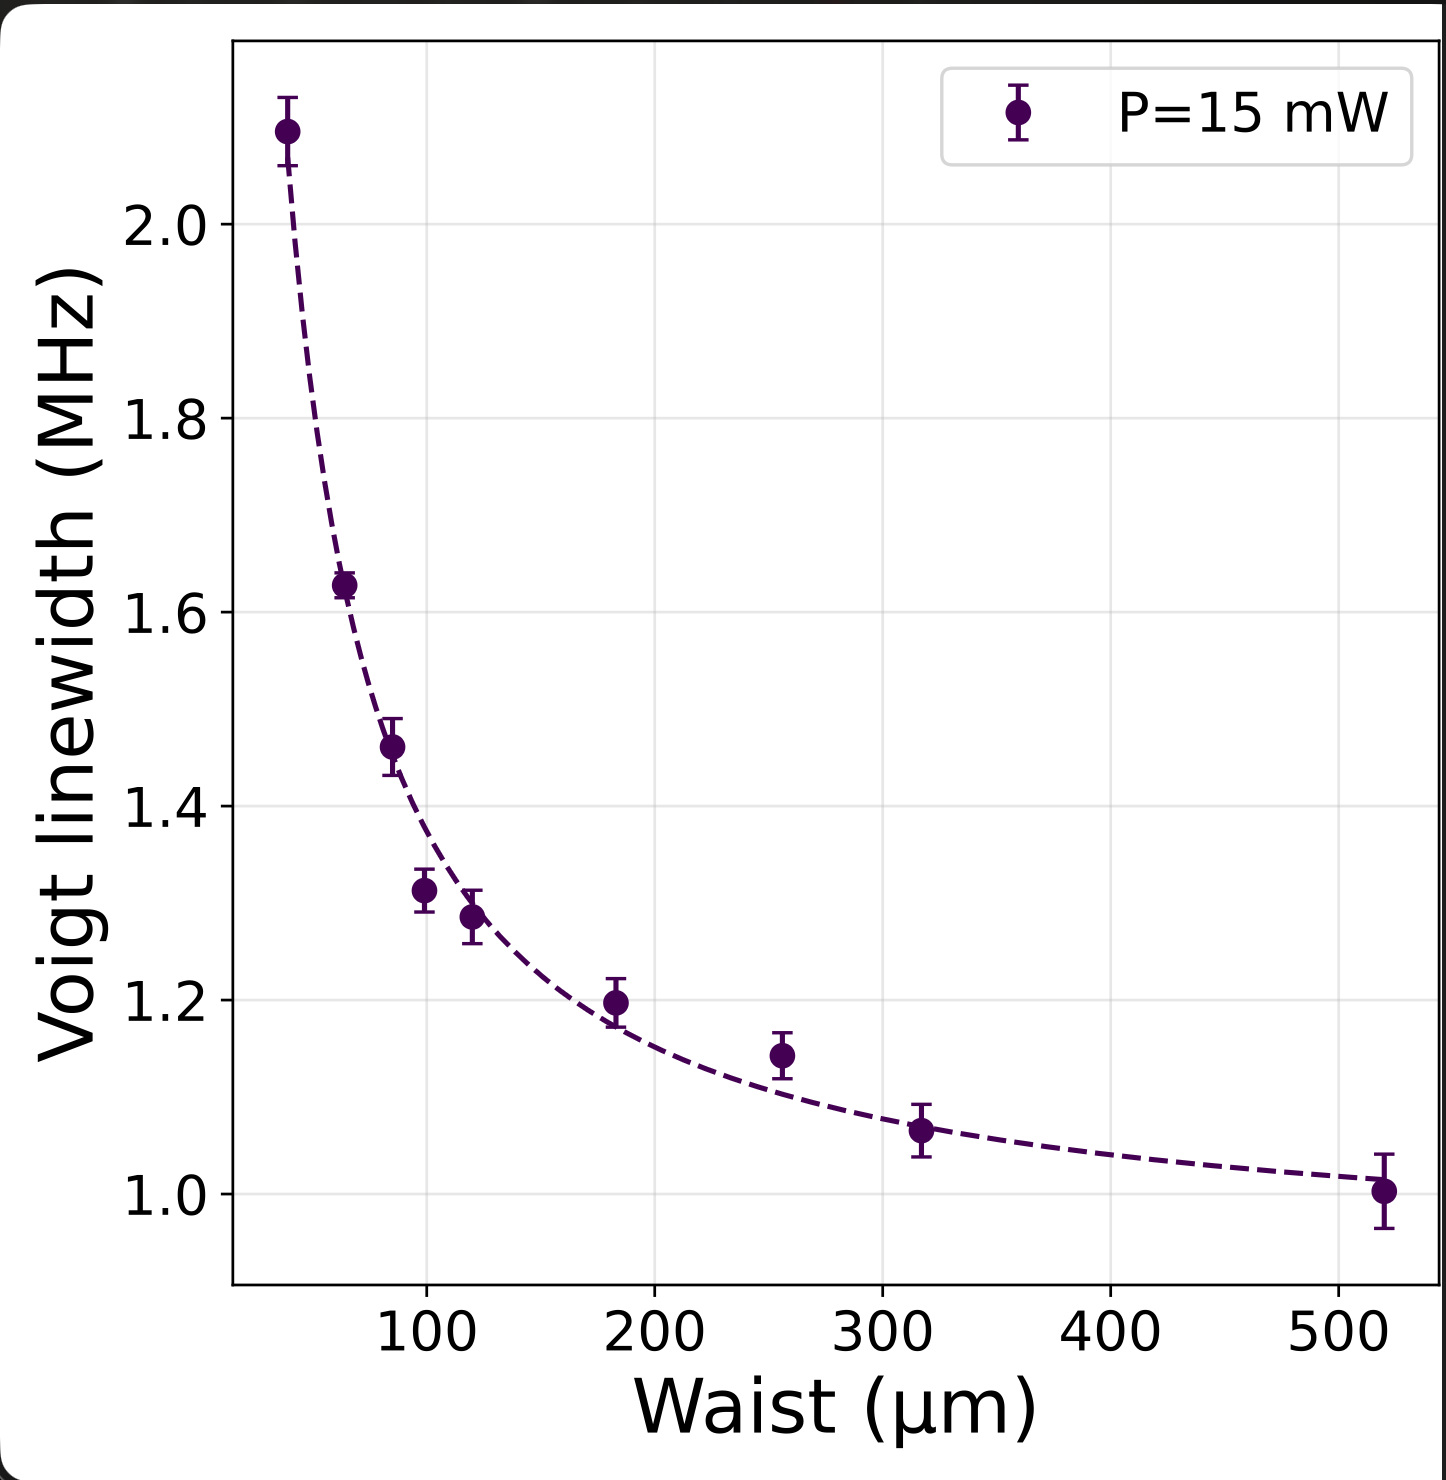

From the graph above any decrease in the waist size shows an exponential increase in the beam size.
Estiamting the beam size and divergence before the lens:


In [2]:

wavelength = 778e-9   # m
focal_length = 100e-3 # m; treated as exact

# Inputs: waist radius, distance from lens to waist, M²
# Uncertainties are assumed independent.
measurements = {
    "x": {
        "values": np.array([69e-6, 123e-3, 1.2]),
        "uncertainties": np.array([6e-6, 3e-3, 0.1]),
    },
    "y": {
        "values": np.array([100e-6, 116e-3, 2.3]),
        "uncertainties": np.array([6e-6, 2e-3, 0.1]),
    },
}


def calculate_beam(parameters):
    """Reconstruct the incoming beam using a thin-lens model."""
    w0, distance, M2 = parameters

    # Downstream effective Rayleigh length
    z_R = np.pi * w0**2 / (M2 * wavelength)

    # Beam radius at the lens: unchanged across a thin lens
    w_lens = w0 * np.sqrt(1 + (distance / z_R)**2)

    # Immediately after the lens, the beam is distance metres
    # before its downstream waist.
    q_out = -distance + 1j * z_R

    # Invert the thin-lens transformation:
    # 1/q_out = 1/q_in - 1/f
    q_in = 1 / (1 / q_out + 1 / focal_length)

    # Positive curvature means the incoming beam is diverging.
    inverse_R_in = np.real(1 / q_in)
    R_in = 1 / inverse_R_in

    # Local rate of increase of beam radius at the lens
    local_angle = w_lens * inverse_R_in  # rad

    # Reconstruct the incoming waist and its far-field divergence
    z_R_in = np.imag(q_in)
    w0_in = np.sqrt(M2 * wavelength * z_R_in / np.pi)
    far_field_half_angle = M2 * wavelength / (np.pi * w0_in)

    return np.array([
        w_lens,
        2 * w_lens,
        R_in,
        local_angle,
        far_field_half_angle,
        2 * far_field_half_angle,
    ])


def propagate_uncertainties(values, uncertainties):
    """First-order propagation using numerical partial derivatives."""
    result = calculate_beam(values)
    jacobian = np.zeros((len(result), len(values)))

    for j in range(len(values)):
        step = abs(values[j]) * 1e-5

        upper = values.copy()
        lower = values.copy()
        upper[j] += step
        lower[j] -= step

        jacobian[:, j] = (
            calculate_beam(upper) - calculate_beam(lower)
        ) / (2 * step)

    result_uncertainty = np.sqrt(
        np.sum((jacobian * uncertainties[None, :])**2, axis=1)
    )

    return result, result_uncertainty


# Label, conversion from SI units, displayed unit
outputs = [
    ("Beam radius at lens",          1e6, "µm"),
    ("Beam diameter at lens",        1e3, "mm"),
    ("Incoming wavefront curvature", 1.0, "m"),
    ("Local expansion angle",        1e3, "mrad"),
    ("Far-field half-angle",         1e3, "mrad"),
    ("Far-field full-angle",         1e3, "mrad"),
]

for axis, measurement in measurements.items():
    result, uncertainty = propagate_uncertainties(
        measurement["values"],
        measurement["uncertainties"],
    )

    print(f"\n{axis.upper()} AXIS — BEFORE THE LENS")

    for i, (label, scale, unit) in enumerate(outputs):
        print(
            f"{label:30s}: "
            f"{result[i] * scale:.3f} ± "
            f"{uncertainty[i] * scale:.3f} {unit}"
        )


X AXIS — BEFORE THE LENS
Beam radius at lens           : 534.220 ± 64.007 µm
Beam diameter at lens         : 1.068 ± 0.128 mm
Incoming wavefront curvature  : 0.499 ± 0.049 m
Local expansion angle         : 1.071 ± 0.161 mrad
Far-field half-angle          : 1.207 ± 0.131 mrad
Far-field full-angle          : 2.414 ± 0.262 mrad

Y AXIS — BEFORE THE LENS
Beam radius at lens           : 668.242 ± 48.994 µm
Beam diameter at lens         : 1.336 ± 0.098 mm
Incoming wavefront curvature  : 0.636 ± 0.059 m
Local expansion angle         : 1.051 ± 0.119 mrad
Far-field half-angle          : 1.353 ± 0.082 mrad
Far-field full-angle          : 2.706 ± 0.163 mrad


Now lets solve for a new lens such that my new q parameter (see referecne for what htis means) has a waist radius of atleast 150 um for both x and y axis and the waist positions are the same, lets play with 150 mm Focal lenth lens to achieve this.

In [3]:

from scipy.optimize import root

wavelength = 778e-9             # m
original_focal_length = 100e-3 # m; treated as exact
target_waist_radius = 150e-6   # m; desired 1/e² radius

# Order: [original waist radius, original waist distance, M²]
measurements = {
    "x": {
        "values": np.array([69e-6, 123e-3, 1.2]),
        "uncertainties": np.array([6e-6, 3e-3, 0.1]),
    },
    "y": {
        "values": np.array([100e-6, 116e-3, 2.3]),
        "uncertainties": np.array([6e-6, 2e-3, 0.1]),
    },
}


def design_lens(values):
    """
    Find a positive lens moved upstream that produces the target
    waist radius at the original waist position.

    Returns:
        new focal length,
        upstream displacement,
        new lens-to-waist distance.
    """
    w0, d, M2 = values

    # Reconstruct the beam immediately before the original lens.
    z_R_old = np.pi * w0**2 / (M2 * wavelength)
    q_out_old = -d + 1j * z_R_old
    q_in_old = 1 / (
        1 / q_out_old + 1 / original_focal_length
    )

    # Rayleigh length required for the target waist radius.
    z_R_target = (
        np.pi * target_waist_radius**2 / (M2 * wavelength)
    )

    def equations(unknowns):
        f_new, shift = unknowns

        # Positive shift means moving the lens upstream.
        q_in_new = q_in_old - shift

        # The original waist position is now d + shift
        # downstream of the new lens.
        q_out_target = -(d + shift) + 1j * z_R_target

        # Thin-lens equation:
        # 1/q_out = 1/q_in - 1/f
        residual = (
            1 / q_in_new
            - 1 / f_new
            - 1 / q_out_target
        )

        # Two equations for the two unknowns.
        return [residual.real, residual.imag]

    solution = root(
        equations,
        x0=[150e-3, 60e-3],  # Initial guesses: focal length, shift
        tol=1e-10,
    )

    if (
        not solution.success
        or np.linalg.norm(equations(solution.x)) > 1e-7
    ):
        raise RuntimeError(f"Lens calculation failed: {solution.message}")

    f_new, shift = solution.x

    if f_new <= 0 or shift < 0:
        raise ValueError(
            "The solver did not find an upstream positive-lens solution."
        )

    return np.array([f_new, shift, d + shift])


def propagate_uncertainties(values, uncertainties):
    """First-order propagation, assuming independent input errors."""
    result = design_lens(values)
    jacobian = np.zeros((len(result), len(values)))

    for j in range(len(values)):
        step = abs(values[j]) * 1e-5

        upper = values.copy()
        lower = values.copy()
        upper[j] += step
        lower[j] -= step

        jacobian[:, j] = (
            design_lens(upper) - design_lens(lower)
        ) / (2 * step)

    result_uncertainty = np.sqrt(
        np.sum((jacobian * uncertainties[None, :])**2, axis=1)
    )

    return result, result_uncertainty


labels = [
    "Required focal length",
    "Move lens upstream by",
    "New lens-to-waist distance",
]

for axis, measurement in measurements.items():
    result, uncertainty = propagate_uncertainties(
        measurement["values"],
        measurement["uncertainties"],
    )

    print(f"\n{axis.upper()} AXIS — SEPARATE DESIGN")
    print(f"Target waist radius: {target_waist_radius * 1e6:.1f} µm")

    for label, value, error in zip(labels, result, uncertainty):
        print(
            f"{label:27s}: "
            f"{value * 1e3:.1f} ± {error * 1e3:.1f} mm"
        )


X AXIS — SEPARATE DESIGN
Target waist radius: 150.0 µm
Required focal length      : 154.5 ± 7.5 mm
Move lens upstream by      : 87.5 ± 13.6 mm
New lens-to-waist distance : 210.5 ± 13.6 mm

Y AXIS — SEPARATE DESIGN
Target waist radius: 150.0 µm
Required focal length      : 133.2 ± 5.4 mm
Move lens upstream by      : 43.4 ± 7.9 mm
New lens-to-waist distance : 159.4 ± 8.1 mm


In [5]:
%matplotlib widget

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider


WAVELENGTH = 778e-9          # m
OLD_FOCAL_LENGTH = 100e-3   # m; assumed exact at 778 nm
NEW_FOCAL_LENGTH = 150e-3   # m; assumed exact at 778 nm
TARGET_RADIUS = 150e-6      # m

# Measured central values: [waist radius (m), old waist position (m), M²].
# Supplied uncertainties: radius ±6 µm; position ±3/±2 mm; M² ±0.1.
MEASUREMENTS = {
    "x": (69e-6, 123e-3, 1.2),
    "y": (100e-6, 116e-3, 2.3),
}
COLORS = {"x": "#0072B2", "y": "#D55E00"}
STYLES = {"x": "-", "y": "--"}


def incoming_q_at_old_lens(waist_radius, waist_position, m2):
    """Undo the original 100 mm lens to reconstruct the incident beam."""
    z_r = np.pi * waist_radius**2 / (m2 * WAVELENGTH)
    q_after_old_lens = -waist_position + 1j * z_r
    return 1 / (1 / q_after_old_lens + 1 / OLD_FOCAL_LENGTH)


Q_IN_OLD = {
    axis: incoming_q_at_old_lens(*values)
    for axis, values in MEASUREMENTS.items()
}


def beam_state(axis, lens_position_m, positions_m):
    """Return radius versus z, downstream waist radius and waist position."""
    m2 = MEASUREMENTS[axis][2]

    # Free-space propagation from the old lens plane to the new lens.
    # For an upstream move, lens_position_m is negative.
    q_before = Q_IN_OLD[axis] + lens_position_m
    q_after = 1 / (1 / q_before - 1 / NEW_FOCAL_LENGTH)

    # Keep the coordinate origin fixed while the lens moves.
    q_z = np.where(
        positions_m < lens_position_m,
        Q_IN_OLD[axis] + positions_m,
        q_after + positions_m - lens_position_m,
    )
    radii = np.sqrt(-m2 * WAVELENGTH / (np.pi * np.imag(1 / q_z)))

    waist_radius = np.sqrt(m2 * WAVELENGTH * q_after.imag / np.pi)
    waist_position = lens_position_m - q_after.real
    return radii, waist_radius, waist_position


def create_plot(initial_position_mm=-80.7):
    """Build the plot and return the figure and live lens-position slider."""
    fig, ax = plt.subplots(figsize=(11, 7))
    fig.subplots_adjust(left=0.10, right=0.97, bottom=0.32, top=0.91)
    ax.set_title("778 nm beam through a movable 150 mm lens")
    ax.set_xlabel("Position relative to OLD lens (mm); negative = upstream")
    ax.set_ylabel("1/e² beam radius (µm)")
    ax.grid(alpha=0.20)

    curves = {}
    markers = {}
    for axis in MEASUREMENTS:
        curves[axis], = ax.plot(
            [], [], color=COLORS[axis], linestyle=STYLES[axis],
            linewidth=2, label=f"New {axis} radius",
        )
        markers[axis], = ax.plot(
            [], [], marker="o" if axis == "x" else "s",
            color=COLORS[axis], linestyle="none", markersize=7,
        )

    # These lines stay fixed: the original measured waists were 7 mm apart.
    ax.axvline(123, color="0.35", linestyle="--", linewidth=1.2,
               label="Original x waist: 123 mm")
    ax.axvline(116, color="0.55", linestyle=":", linewidth=1.5,
               label="Original y waist: 116 mm")
    ax.axhline(TARGET_RADIUS * 1e6, color="0.4", linestyle="-.",
               linewidth=1, label="Target radius: 150 µm")
    lens_line = ax.axvline(initial_position_mm, color="0.15",
                           linewidth=1.5, label="New lens")
    ax.legend(loc="upper right", fontsize=8, ncol=2)

    info_x = fig.text(0.10, 0.23, "", fontsize=10)
    info_y = fig.text(0.10, 0.18, "", fontsize=10)
    fig.text(0.10, 0.125,
             "Circles/squares mark new waists. All z positions use the old lens as zero.",
             fontsize=9)

    slider_ax = fig.add_axes([0.24, 0.055, 0.60, 0.035])
    lens_slider = Slider(
        slider_ax, "Lens position (mm)", -250, 50,
        valinit=initial_position_mm, valstep=0.1, valfmt="%0.1f",
    )

    # A fixed spatial view makes it easy to compare different positions.
    sample_z = np.linspace(-270e-3, 360e-3, 2400)
    ax.set_xlim(sample_z[0] * 1e3, sample_z[-1] * 1e3)

    def update(_):
        lens_position = lens_slider.val * 1e-3
        # Include the exact lens plane in the sampling grid.
        z = np.sort(np.append(sample_z, lens_position))
        maximum_radius = TARGET_RADIUS

        for axis, info in [("x", info_x), ("y", info_y)]:
            radii, waist_radius, waist_z = beam_state(axis, lens_position, z)
            curves[axis].set_data(z * 1e3, radii * 1e6)
            markers[axis].set_data([waist_z * 1e3], [waist_radius * 1e6])
            maximum_radius = max(maximum_radius, float(np.max(radii)))
            old_z = MEASUREMENTS[axis][1]
            info.set_text(
                f"{axis.upper()}: waist radius = {waist_radius * 1e6:.1f} µm; "
                f"waist z = {waist_z * 1e3:.1f} mm; "
                f"change from original = {(waist_z - old_z) * 1e3:+.1f} mm; "
                f"lens-to-waist = {(waist_z - lens_position) * 1e3:.1f} mm"
            )

        lens_line.set_xdata([lens_slider.val, lens_slider.val])
        ax.set_ylim(0, maximum_radius * 1e6 * 1.08)
        fig.canvas.draw_idle()

    lens_slider.on_changed(update)
    # Retain the slider and callback, including when run in a notebook.
    fig._beam_lens_slider = lens_slider
    fig._beam_update = update
    update(None)
    return fig, lens_slider




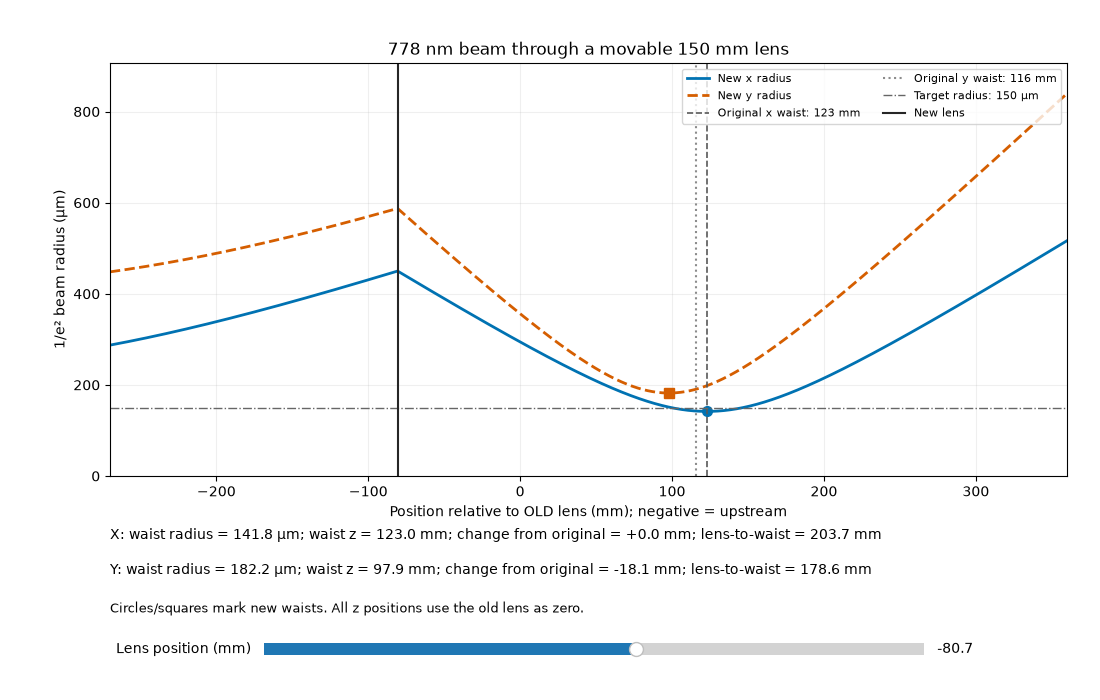

In [6]:
plt.close("all")
figure, lens_slider = create_plot(initial_position_mm=-80.7)
plt.show()
